# Chapitre 7 - Exercices 7.1 à 7.5

Ces exercices établissent les résultats théoriques sur lesquels reposent les critères
analytiques et la validation croisée du chapitre :

* **7.1** : l'estimation de l'erreur intra-échantillon (7.24) ;
* **7.2** : la décomposition de l'erreur de classement et l'interaction biais-variance en
  perte 0-1 ;
* **7.3** : la formule leave-one-out sans réajustement pour un lisseur linéaire ;
* **7.4** : l'optimisme moyen $\frac2N\sum\mathrm{Cov}(\hat y_i, y_i)$ ;
* **7.5** : $\sum\mathrm{Cov}(\hat y_i, y_i) = \mathrm{trace}(\mathbf S)\sigma^2_\varepsilon$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import ch07_selection as sel
set_style()

## Exercice 7.1 : Estimation de l'erreur intra-échantillon

**Énoncé.** Établir l'estimation (7.24) de l'erreur intra-échantillon :
$\mathbb E_{\mathbf y}(\mathrm{Err}_{\mathrm{in}}) = \mathbb E_{\mathbf y}(\overline{\mathrm{err}}) + 2\frac dN\sigma^2_\varepsilon$
pour un ajustement linéaire à $d$ paramètres (fonctions de base fixées) dans le modèle
$Y = f(X) + \varepsilon$.

**Cadre et notations.** Les entrées $x_1, \dots, x_N$ sont fixées. On note
$\mathbf f = (f(x_1), \dots, f(x_N))^T$, $\mathbf y = \mathbf f + \boldsymbol\varepsilon$ avec
$\boldsymbol\varepsilon$ centré, de matrice de covariance $\sigma^2_\varepsilon I_N$. Le
modèle est ajusté par moindres carrés sur $d$ fonctions de base linéairement
indépendantes : $\hat{\mathbf y} = \mathbf H\mathbf y$ où $\mathbf H$ est la matrice
chapeau, **projecteur orthogonal** de rang $d$ ($\mathbf H^T = \mathbf H$, $\mathbf H^2 = \mathbf H$,
$\mathrm{trace}(\mathbf H) = d$).

Pour la perte quadratique,
$\overline{\mathrm{err}} = \frac1N\|\mathbf y - \hat{\mathbf y}\|^2$ et
$\mathrm{Err}_{\mathrm{in}} = \frac1N\mathbb E_{\mathbf Y^0}\|\mathbf Y^0 - \hat{\mathbf y}\|^2$,
où $\mathbf Y^0 = \mathbf f + \boldsymbol\varepsilon^0$ est un nouveau vecteur de réponses,
indépendant de $\mathbf y$.

**Lemme (espérance d'une forme quadratique).** Pour toute matrice $\mathbf A$ (non
aléatoire), $\mathbb E\|\mathbf A\mathbf y\|^2 = \|\mathbf A\mathbf f\|^2 + \sigma^2_\varepsilon\,\mathrm{trace}(\mathbf A^T\mathbf A)$.

*Preuve.* On développe $\|\mathbf A\mathbf f + \mathbf A\boldsymbol\varepsilon\|^2 = \|\mathbf A\mathbf f\|^2 + 2\mathbf f^T\mathbf A^T\mathbf A\boldsymbol\varepsilon + \boldsymbol\varepsilon^T\mathbf A^T\mathbf A\boldsymbol\varepsilon$.
Le terme du milieu est d'espérance nulle (linéarité, $\mathbb E\boldsymbol\varepsilon = 0$).
Pour le dernier, un scalaire est égal à sa trace et la trace est invariante par
permutation circulaire :
$\mathbb E[\boldsymbol\varepsilon^T\mathbf M\boldsymbol\varepsilon] = \mathbb E[\mathrm{trace}(\mathbf M\boldsymbol\varepsilon\boldsymbol\varepsilon^T)] = \mathrm{trace}(\mathbf M\,\mathbb E[\boldsymbol\varepsilon\boldsymbol\varepsilon^T]) = \sigma^2_\varepsilon\mathrm{trace}(\mathbf M)$
avec $\mathbf M = \mathbf A^T\mathbf A$. $\square$

**Erreur d'apprentissage.** $\mathbf y - \hat{\mathbf y} = (I - \mathbf H)\mathbf y$, et
$I - \mathbf H$ est aussi un projecteur orthogonal, de rang $N - d$, donc
$(I - \mathbf H)^T(I - \mathbf H) = I - \mathbf H$ et $\mathrm{trace}(I - \mathbf H) = N - d$.
Le lemme donne

$$\mathbb E_{\mathbf y}(\overline{\mathrm{err}}) = \frac1N\|(I - \mathbf H)\mathbf f\|^2 + \frac{N - d}N\sigma^2_\varepsilon.$$

**Erreur intra-échantillon.** On écrit $\mathbf Y^0 - \hat{\mathbf y} = \boldsymbol\varepsilon^0 + (\mathbf f - \mathbf H\mathbf y)$.
Comme $\boldsymbol\varepsilon^0$ est centré et indépendant de $\mathbf y$, le double produit
est d'espérance nulle et
$\mathbb E_{\mathbf Y^0}\|\mathbf Y^0 - \hat{\mathbf y}\|^2 = N\sigma^2_\varepsilon + \|\mathbf f - \mathbf H\mathbf y\|^2$.
Puis, en écrivant $\mathbf f - \mathbf H\mathbf y = (I - \mathbf H)\mathbf f - \mathbf H\boldsymbol\varepsilon$
et en appliquant le même raisonnement ($\mathbf H^T\mathbf H = \mathbf H$, de trace $d$) :

$$\mathbb E_{\mathbf y}(\mathrm{Err}_{\mathrm{in}}) = \sigma^2_\varepsilon + \frac1N\|(I - \mathbf H)\mathbf f\|^2 + \frac dN\sigma^2_\varepsilon.$$

**Conclusion.** Par différence, le terme de biais $\frac1N\|(I - \mathbf H)\mathbf f\|^2$
disparaît :

$$\mathbb E_{\mathbf y}(\mathrm{Err}_{\mathrm{in}}) - \mathbb E_{\mathbf y}(\overline{\mathrm{err}})
= \sigma^2_\varepsilon + \frac dN\sigma^2_\varepsilon - \frac{N - d}N\sigma^2_\varepsilon = 2\cdot\frac dN\,\sigma^2_\varepsilon,$$

ce qui est exactement (7.24). L'erreur d'apprentissage sous-estime le bruit d'un facteur
$(N - d)/N$, et l'erreur intra-échantillon le surestime de $d/N$ (variance de
l'estimateur) : l'écart total est $2d\sigma^2_\varepsilon/N$.

**Vérification numérique.** Régression polynomiale de degré $d - 1$ sur $N = 30$ points
fixés, $f(x) = e^{x}\cos(3x)$, $\sigma_\varepsilon = 0{,}5$. On compare les espérances
simulées des deux erreurs aux formules exactes ci-dessus.

In [2]:
rng = np.random.RandomState(0)
N, sig, n_rep = 30, 0.5, 5000
x = np.sort(rng.uniform(-1, 1, N))
f = np.exp(x) * np.cos(3 * x)
ds = np.arange(1, 13)
sim_err, sim_in, th_err, th_in = [], [], [], []
for d in ds:
    H = sel.hat_matrix(np.vander(x, d, increasing=True), intercept=False)
    bias = np.sum(((np.eye(N) - H) @ f) ** 2) / N
    Y = f + sig * rng.randn(n_rep, N)
    Yhat = Y @ H
    sim_err.append(np.mean((Y - Yhat) ** 2))
    sim_in.append(sig ** 2 + np.mean((f - Yhat) ** 2))     # espérance sur Y0 calculée exactement
    th_err.append(bias + (N - d) / N * sig ** 2)
    th_in.append(sig ** 2 + bias + d / N * sig ** 2)

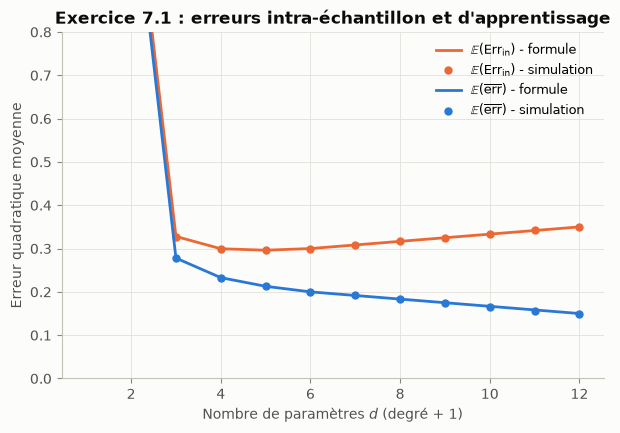

In [3]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(ds, th_in, color=ORANGE, label=r"$\mathbb{E}(\mathrm{Err}_{\mathrm{in}})$ - formule")
ax.plot(ds, sim_in, "o", color=ORANGE, label=r"$\mathbb{E}(\mathrm{Err}_{\mathrm{in}})$ - simulation")
ax.plot(ds, th_err, color=BLUE, label=r"$\mathbb{E}(\overline{\mathrm{err}})$ - formule")
ax.plot(ds, sim_err, "o", color=BLUE, label=r"$\mathbb{E}(\overline{\mathrm{err}})$ - simulation")
ax.set_ylim(0, 0.8)
ax.set_xlabel("Nombre de paramètres $d$ (degré + 1)")
ax.set_ylabel("Erreur quadratique moyenne")
ax.set_title("Exercice 7.1 : erreurs intra-échantillon et d'apprentissage")
ax.legend()
plt.show()

In [4]:
gap = np.array(sim_in) - np.array(sim_err)
print("écart simulé / (2 d sigma^2 / N) :", np.round(gap / (2 * ds * sig ** 2 / N), 3))

écart simulé / (2 d sigma^2 / N) : [0.838 0.976 1.014 1.017 0.998 0.998 0.998 1.005 1.    1.    1.011 1.004]


Les rapports valent 1 aux fluctuations de Monte-Carlo près ; l'écart plus marqué pour
$d = 1$ vient de ce que l'optimisme y est minuscule ($2\sigma^2_\varepsilon/N \approx 0{,}017$)
devant les erreurs elles-mêmes, si bien que l'erreur relative de simulation est plus grande.

> **À retenir.** Pour un ajustement linéaire à $d$ paramètres, les termes de biais se
> compensent exactement : l'optimisme moyen vaut $2d\sigma^2_\varepsilon/N$, quel que soit
> $f$. C'est la justification du critère $C_p$.

## Exercice 7.2 : Erreur de classement, biais et variance en perte 0-1

**Énoncé.** Pour $Y\in\{0,1\}$ avec $\Pr(Y = 1\mid x_0) = f(x_0)$, on note
$\hat G(x) = I(\hat f(x) > 1/2)$ le classifieur estimé, $G(x) = I(f(x) > 1/2)$ le classifieur
de Bayes et $\mathrm{Err}_B(x_0) = \Pr(Y \neq G(x_0)\mid X = x_0)$ l'erreur de Bayes
(irréductible) en $x_0$. Montrer que

$$\mathrm{Err}(x_0) = \Pr(Y\neq\hat G(x_0)\mid X = x_0) = \mathrm{Err}_B(x_0) + |2f(x_0) - 1|\,\Pr(\hat G(x_0)\neq G(x_0)\mid X = x_0). \tag{7.62}$$

Puis, avec l'approximation $\hat f(x_0)\sim\mathcal N(\mathbb E\hat f(x_0), \mathrm{Var}\hat f(x_0))$,
montrer que

$$\Pr(\hat G(x_0)\neq G(x_0)\mid X = x_0) \approx \Phi\left(\frac{\mathrm{sign}(\frac12 - f(x_0))(\mathbb E\hat f(x_0) - \frac12)}{\sqrt{\mathrm{Var}\hat f(x_0)}}\right), \tag{7.63}$$

où $\Phi$ est la fonction de répartition de la loi normale centrée réduite.

**Rappels.** Le point $x_0$ est fixé ; on abrège $f = f(x_0)$. La réponse test $Y$ est
indépendante de l'échantillon d'apprentissage, donc de $\hat G(x_0)$, qui ne prend que
deux valeurs : soit $\hat G(x_0) = G(x_0)$, soit $\hat G(x_0) = 1 - G(x_0)$. Le
classifieur de Bayes choisit la classe la plus probable, donc
$\mathrm{Err}_B = \min(f, 1 - f)$ et $\Pr(Y = G(x_0)) = \max(f, 1-f) = 1 - \mathrm{Err}_B$.

**Preuve de (7.62).** Notons $q = \Pr(\hat G(x_0)\neq G(x_0))$. Par la formule des
probabilités totales, en conditionnant par l'événement $\{\hat G(x_0) = G(x_0)\}$ et en
utilisant l'indépendance entre $Y$ et $\hat G(x_0)$ :

$$
\begin{aligned}
\mathrm{Err}(x_0) &= (1 - q)\Pr(Y\neq G(x_0)) + q\,\Pr(Y\neq 1 - G(x_0)) \\
&= (1 - q)\,\mathrm{Err}_B + q\,(1 - \mathrm{Err}_B) \\
&= \mathrm{Err}_B + q\,(1 - 2\,\mathrm{Err}_B).
\end{aligned}
$$

Enfin $1 - 2\min(f, 1-f) = \max(f, 1-f) - \min(f, 1-f) = |f - (1 - f)| = |2f - 1|$, d'où (7.62).

**Preuve de (7.63).** On distingue selon le côté de $1/2$ où se trouve $f$. Notons
$\mu = \mathbb E\hat f(x_0)$, $s = \sqrt{\mathrm{Var}\hat f(x_0)}$, et rappelons que si
$Z\sim\mathcal N(\mu, s^2)$, alors $\Pr(Z\leq t) = \Phi((t - \mu)/s)$ et
$\Pr(Z > t) = 1 - \Phi((t-\mu)/s) = \Phi((\mu - t)/s)$ par symétrie de la loi normale.

* Si $f < 1/2$ : $G(x_0) = 0$ et l'erreur $\hat G\neq G$ signifie $\hat f(x_0) > 1/2$, de
  probabilité $\Phi\big((\mu - \frac12)/s\big)$ ; ici $\mathrm{sign}(\frac12 - f) = +1$.
* Si $f > 1/2$ : $G(x_0) = 1$ et l'erreur signifie $\hat f(x_0)\leq 1/2$, de probabilité
  $\Phi\big((\frac12 - \mu)/s\big) = \Phi\big(-(\mu - \frac12)/s\big)$ ; ici $\mathrm{sign}(\frac12 - f) = -1$.

Les deux cas s'écrivent $\Phi\big(\mathrm{sign}(\frac12 - f)(\mu - \frac12)/s\big)$ : c'est (7.63).

> **Intuition.** Le numérateur $\mathrm{sign}(\frac12 - f)(\mathbb E\hat f - \frac12)$ joue
> le rôle d'un « biais de frontière » : il est **négatif** si $\hat f$ est en moyenne du bon
> côté de $1/2$, **positif** sinon. Biais et variance se combinent alors de façon
> **multiplicative** (quotient), et non additive :
> * bon côté (numérateur $< 0$) : réduire la variance fait tendre $\Phi$ vers 0 ;
> * mauvais côté (numérateur $> 0$) : **augmenter** la variance fait baisser $\Phi$ vers
>   $1/2$, car elle augmente la chance de tomber du bon côté !

**Vérification numérique.** On simule un estimateur concret : $\hat f(x_0)$ est la moyenne
de $k$ réponses binaires $Y_j\sim\mathcal B(f(x_{(j)}))$ aux $k$ voisins de $x_0$, avec
$f(x_0) = 0{,}35$ et des voisins de probabilité moyenne $\bar f$ (biais
$\bar f - f(x_0)$). Sa loi est approximativement normale pour $k$ assez grand. On compare
l'erreur de classement simulée à (7.62)-(7.63).

In [5]:
rng = np.random.RandomState(0)
f0, n_rep = 0.35, 200000
rows = []
for fbar in [0.30, 0.45, 0.55, 0.65]:
    for k in [5, 15, 41, 101]:
        fhat = rng.binomial(k, fbar, n_rep) / k
        Ghat = (fhat > 0.5).astype(int)
        Y = (rng.rand(n_rep) < f0).astype(int)
        err_sim = np.mean(Y != Ghat)
        mu, s = fbar, np.sqrt(fbar * (1 - fbar) / k)
        q_approx = norm.cdf(np.sign(0.5 - f0) * (mu - 0.5) / s)
        q_exact = np.mean(Ghat != 0)              # G(x0) = 0 car f0 < 1/2
        err_62 = min(f0, 1 - f0) + abs(2 * f0 - 1) * q_exact
        err_63 = min(f0, 1 - f0) + abs(2 * f0 - 1) * q_approx
        rows.append((fbar, k, err_sim, err_62, err_63))
import pandas as pd
pd.DataFrame(rows, columns=["E f_hat", "k", "Err simulée", "(7.62) avec q exact", "(7.62)+(7.63)"]).round(4)

,E f_hat,k,Err simulée,(7.62) avec q exact,(7.62)+(7.63)
0,0.30,5,0.4000,0.3990,0.3994
1,0.30,15,0.3630,0.3649,0.3636
2,0.30,41,0.3511,0.3511,0.3508
3,0.30,101,0.3500,0.3500,0.3500
4,0.45,5,0.4719,0.4719,0.4733
5,0.45,15,0.4539,0.4541,0.4546
6,0.45,41,0.4269,0.4271,0.4280
7,0.45,101,0.3972,0.3969,0.3969
8,0.55,5,0.5278,0.5281,0.5267
9,0.55,15,0.5494,0.5464,0.5454


La formule (7.62) est exacte (aux fluctuations de simulation près) ; l'approximation
normale (7.63) est bonne dès que $k$ est modéré (l'écart restant pour $k$ petit vient de la
discrétisation de la loi binomiale). Observons maintenant l'effet de la variance selon le
côté où se trouve $\mathbb E\hat f$.

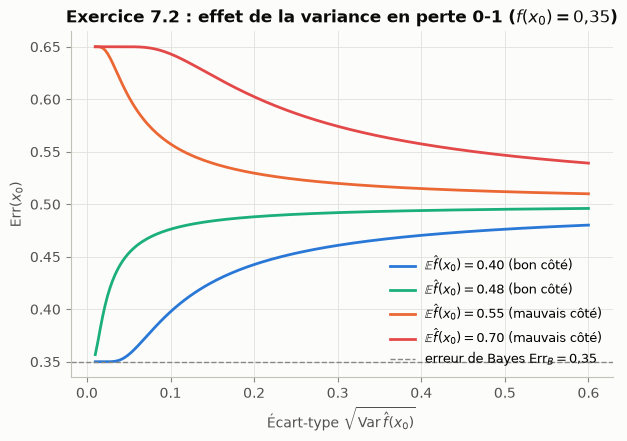

In [6]:
sds = np.linspace(0.01, 0.6, 200)
fig, ax = plt.subplots(figsize=(7, 4.5))
for mu, c in [(0.40, BLUE), (0.48, COLORS[2]), (0.55, ORANGE), (0.70, COLORS[7])]:
    err = min(f0, 1 - f0) + abs(2 * f0 - 1) * norm.cdf(np.sign(0.5 - f0) * (mu - 0.5) / sds)
    side = "bon côté" if mu < 0.5 else "mauvais côté"
    ax.plot(sds, err, color=c, label=r"$\mathbb{E}\hat f(x_0) = %.2f$ (%s)" % (mu, side))
ax.axhline(min(f0, 1 - f0), color=GRAY, ls="--", lw=1, label=r"erreur de Bayes $\mathrm{Err}_B = 0{,}35$")
ax.set_xlabel(r"Écart-type $\sqrt{\mathrm{Var}\,\hat f(x_0)}$")
ax.set_ylabel(r"$\mathrm{Err}(x_0)$")
ax.set_title("Exercice 7.2 : effet de la variance en perte 0-1 ($f(x_0)=0{,}35$)")
ax.legend()
plt.show()

Quand $\mathbb E\hat f(x_0)$ est du **bon** côté de $1/2$, l'erreur croît avec la variance ;
quand il est du **mauvais** côté, l'erreur **décroît** avec la variance, vers la valeur
« pile ou face » $\mathrm{Err}_B + |2f-1|/2 = 1/2$.

> **À retenir.** En perte 0-1,
> $\mathrm{Err}(x_0) = \mathrm{Err}_B(x_0) + |2f(x_0) - 1|\Pr(\hat G(x_0)\neq G(x_0))$ et,
> en approximation normale, $\Pr(\hat G\neq G)\approx\Phi(\text{biais de frontière}/\text{écart-type})$.
> Seul le **signe** du biais par rapport à $1/2$ compte, et biais et variance interagissent
> de façon multiplicative : c'est pourquoi la courbe d'erreur de classement de la figure
> 7.3 n'est pas la somme du biais et de la variance.

## Exercice 7.3 : Validation croisée leave-one-out pour un lisseur linéaire

**Énoncé.** Soit $\hat{\mathbf f} = \mathbf S\mathbf y$ un lissage linéaire de $\mathbf y$,
et $S_{ii}$ le $i$-ème élément diagonal de $\mathbf S$.

(a) Montrer que, pour $\mathbf S$ issue d'une projection des moindres carrés ou d'une
spline cubique de lissage, le résidu de validation croisée s'écrit
$$y_i - \hat f^{-i}(x_i) = \frac{y_i - \hat f(x_i)}{1 - S_{ii}}. \tag{7.64}$$
(b) En déduire que $|y_i - \hat f^{-i}(x_i)|\geq|y_i - \hat f(x_i)|$.

(c) Trouver des conditions générales sur un lisseur $\mathbf S$ pour que (7.64) soit vraie.

**Rappels.** $\hat f^{-i}$ désigne le modèle ajusté **sans** l'observation $i$, avec le
même paramètre de réglage. Les deux méthodes de (a) sont des **moindres carrés
pénalisés** : $\hat f$ minimise
$$C(f; \mathbf y) = \sum_{j=1}^N (y_j - f(x_j))^2 + J(f)$$
sur une classe de fonctions $\mathcal F$, avec $J \equiv 0$ et $\mathcal F$ un espace
vectoriel de dimension finie pour les moindres carrés, et $J(f) = \lambda\int f''^2$ sur
les fonctions deux fois dérivables pour la spline de lissage. Dans les deux cas le
minimiseur est unique (si $\mathbf X$ est de plein rang, resp. $N \geq 3$ points
distincts) et $\hat{\mathbf f} = \mathbf S\mathbf y$ avec $\mathbf S$ indépendante de $\mathbf y$.

**(a) Étape 1 : le lemme « leave-one-out ».** Posons $\mathbf y^*$ le vecteur $\mathbf y$
dans lequel on remplace $y_i$ par $y_i^* = \hat f^{-i}(x_i)$. Montrons que $\hat f^{-i}$
minimise $C(\cdot\,; \mathbf y^*)$. Pour toute $f\in\mathcal F$,

$$C(f; \mathbf y^*) \geq \sum_{j\neq i}(y_j - f(x_j))^2 + J(f) \geq \sum_{j\neq i}(y_j - \hat f^{-i}(x_j))^2 + J(\hat f^{-i}) = C(\hat f^{-i}; \mathbf y^*).$$

La première inégalité vient de ce qu'on a retiré un carré (positif) ; la seconde de la
définition de $\hat f^{-i}$ (minimiseur du critère sans l'observation $i$) ; l'égalité finale
de ce que le terme $i$ de $C(\hat f^{-i}; \mathbf y^*)$ vaut $(\hat f^{-i}(x_i) - \hat f^{-i}(x_i))^2 = 0$.
Par unicité du minimiseur, l'ajustement sur $\mathbf y^*$ est $\hat f^{-i}$, donc
$\hat f^{-i}(x_i) = (\mathbf S\mathbf y^*)_i$.

**(a) Étape 2 : calcul.** Les vecteurs $\mathbf y^*$ et $\mathbf y$ ne diffèrent que par
la coordonnée $i$, donc

$$\hat f^{-i}(x_i) = \sum_{j\neq i}S_{ij}y_j + S_{ii}\hat f^{-i}(x_i) = \hat f(x_i) - S_{ii}y_i + S_{ii}\hat f^{-i}(x_i).$$

Si $S_{ii}\neq 1$, on isole $\hat f^{-i}(x_i)$ :
$\hat f^{-i}(x_i) = \dfrac{\hat f(x_i) - S_{ii}y_i}{1 - S_{ii}}$, puis

$$y_i - \hat f^{-i}(x_i) = \frac{(1 - S_{ii})y_i - \hat f(x_i) + S_{ii}y_i}{1 - S_{ii}} = \frac{y_i - \hat f(x_i)}{1 - S_{ii}}. \qquad\square$$

**(b)** Il suffit de montrer que $0\leq S_{ii} < 1$, car alors $0 < 1 - S_{ii}\leq 1$ et
diviser par $1 - S_{ii}$ augmente la valeur absolue.

* **Projection** : $\mathbf S = \mathbf H$ est symétrique et idempotente, donc
  $S_{ii} = (\mathbf H^2)_{ii} = \sum_j S_{ij}^2 \geq S_{ii}^2$, ce qui donne $0\leq S_{ii}\leq 1$.
* **Spline de lissage** : $\mathbf S = (I + \lambda\mathbf K)^{-1}$ avec $\mathbf K$
  symétrique positive ; ses valeurs propres $1/(1 + \lambda d_k)$ sont dans $]0, 1]$. Par
  le quotient de Rayleigh, $S_{ii} = \mathbf e_i^T\mathbf S\mathbf e_i\in\,]0, 1]$.

Le cas $S_{ii} = 1$ (observation qui détermine à elle seule sa prédiction, par exemple
un point de levier maximal) rend $\hat f^{-i}(x_i)$ non défini par la formule et est exclu.
On a donc $|y_i - \hat f^{-i}(x_i)| = |y_i - \hat f(x_i)|/(1 - S_{ii}) \geq |y_i - \hat f(x_i)|$ :
un résidu de validation croisée est toujours **plus grand** que le résidu d'apprentissage.

**(c) Condition générale.** Pour un lisseur linéaire quelconque, notons $\mathbf s_i^{(-i)}$
les poids (sur les $y_j$, $j\neq i$) qui donnent la prédiction leave-one-out :
$\hat f^{-i}(x_i) = \sum_{j\neq i}s^{(-i)}_{ij}y_j$. Alors (7.64) est vraie pour tout $\mathbf y$
**si et seulement si**

$$s^{(-i)}_{ij} = \frac{S_{ij}}{1 - S_{ii}}\qquad\text{pour tout } j\neq i,$$

c'est-à-dire si la prédiction sans $i$ s'obtient en **supprimant le poids de $y_i$ et en
renormalisant** les autres poids de la ligne $i$.

*Preuve.* Si les poids sont renormalisés,
$y_i - \sum_{j\neq i}\frac{S_{ij}y_j}{1 - S_{ii}} = \frac{(1 - S_{ii})y_i - (\hat f(x_i) - S_{ii}y_i)}{1 - S_{ii}} = \frac{y_i - \hat f(x_i)}{1 - S_{ii}}$.
Réciproquement, si (7.64) vaut pour tout $\mathbf y$, alors
$\hat f^{-i}(x_i) = y_i - \frac{y_i - \sum_j S_{ij}y_j}{1 - S_{ii}} = \sum_{j\neq i}\frac{S_{ij}}{1 - S_{ii}}y_j$
(le coefficient de $y_i$ s'annule), et l'identification des coefficients donne la condition.

Le raisonnement de (a) montre que cette condition est satisfaite dès que la prédiction en
$x_i$ est obtenue en minimisant un critère de **moindres carrés (éventuellement pondérés)
pénalisés**, dans lequel l'observation $i$ n'intervient que par un terme
$w_i(y_i - f(x_i))^2$ et où la supprimer revient à annuler ce terme, la pénalité et la classe
de fonctions ne dépendant pas des données. C'est le cas de la régression ridge, des
splines de lissage, de la régression locale (linéaire ou constante, c'est-à-dire le
lisseur à noyau de Nadaraya-Watson). Ce n'est **pas** le cas des $k$ plus proches voisins :
retirer $x_i$ fait **entrer un nouveau voisin** dans le voisinage, au lieu de simplement
renormaliser les poids.

**Vérification numérique.** On compare, pour plusieurs lisseurs, les résidus
leave-one-out obtenus en **réajustant** $N$ fois et ceux donnés par (7.64).

In [7]:
rng = np.random.RandomState(0)
N = 40
x = np.sort(rng.rand(N))
y = np.sin(2 * np.pi * x) + 0.3 * rng.randn(N)
X3 = np.vander(x, 4, increasing=True)[:, 1:]          # polynôme de degré 3

def ridge_S(X, lam):
    Z = np.column_stack([np.ones(len(X)), X])
    D = np.diag([0.0] + [lam] * X.shape[1])            # constante non pénalisée
    return Z @ np.linalg.solve(Z.T @ Z + D, Z.T)

def nw_S(xa, xb, h=0.08):
    W = np.exp(-0.5 * ((xb[:, None] - xa[None, :]) / h) ** 2)
    return W / W.sum(1, keepdims=True)

def loo_brute(fit_predict):
    return np.array([y[i] - fit_predict(np.delete(np.arange(N), i), i) for i in range(N)])

smoothers = {
    "moindres carrés (cubique)": (sel.hat_matrix(X3),
        lambda tr, i: sel.ols_fit_predict(X3[tr], y[tr], X3[i:i + 1])[0]),
    "ridge (lambda = 0,1)": (ridge_S(X3, 0.1),
        lambda tr, i: (np.r_[1, X3[i]] @ np.linalg.solve(
            np.column_stack([np.ones(len(tr)), X3[tr]]).T @ np.column_stack([np.ones(len(tr)), X3[tr]])
            + np.diag([0, .1, .1, .1]), np.column_stack([np.ones(len(tr)), X3[tr]]).T @ y[tr]))),
    "spline de lissage": (sel.smoothing_spline_matrix(x, 1e-4),
        lambda tr, i: sel.smoothing_spline_predict(x[tr], y[tr], 1e-4, x[i])[0]),
    "noyau de Nadaraya-Watson": (nw_S(x, x),
        lambda tr, i: (nw_S(x[tr], x[i:i + 1]) @ y[tr])[0]),
    "5 plus proches voisins": (sel.knn_smoother_matrix(x, 5),
        lambda tr, i: sel.knn_regression(x[tr], y[tr], x[i:i + 1], 5)[0]),
}
for name, (S, fp) in smoothers.items():
    brute = loo_brute(fp)
    short = sel.loo_residuals(y, S)
    print("%-28s écart max |réajustement - (7.64)| = %.2e" % (name, np.max(np.abs(brute - short))))

moindres carrés (cubique)    écart max |réajustement - (7.64)| = 1.53e-14
ridge (lambda = 0,1)         écart max |réajustement - (7.64)| = 4.00e-15
spline de lissage            écart max |réajustement - (7.64)| = 3.31e-13
noyau de Nadaraya-Watson     écart max |réajustement - (7.64)| = 3.05e-16
5 plus proches voisins       écart max |réajustement - (7.64)| = 2.35e-01


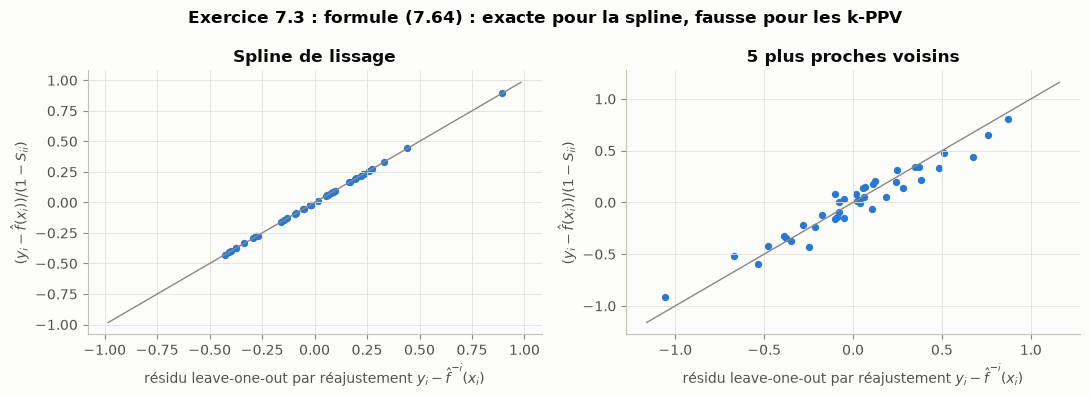

In [8]:
S5 = sel.knn_smoother_matrix(x, 5)
brute_knn = loo_brute(smoothers["5 plus proches voisins"][1])
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
Ss = smoothers["spline de lissage"][0]
for ax, (S, br, t) in zip(axes, [(Ss, loo_brute(smoothers["spline de lissage"][1]), "Spline de lissage"),
                                 (S5, brute_knn, "5 plus proches voisins")]):
    ax.scatter(br, sel.loo_residuals(y, S), s=18, color=BLUE)
    lim = np.abs(br).max() * 1.1
    ax.plot([-lim, lim], [-lim, lim], color=GRAY, lw=1)
    ax.set_xlabel(r"résidu leave-one-out par réajustement $y_i - \hat f^{-i}(x_i)$")
    ax.set_ylabel(r"$(y_i - \hat f(x_i))/(1 - S_{ii})$")
    ax.set_title(t)
fig.suptitle("Exercice 7.3 : formule (7.64) : exacte pour la spline, fausse pour les k-PPV", fontweight="bold")
plt.tight_layout()
plt.show()

Pour les quatre premiers lisseurs (moindres carrés pénalisés ou pondérés), l'écart est de
l'ordre de la précision machine ; pour les $k$-PPV, la formule est fausse, comme prévu.
Vérifions enfin (b) sur la spline : tous les résidus leave-one-out dominent les résidus
d'apprentissage.

In [ ]:
r_fit = y - Ss @ y
r_loo = sel.loo_residuals(y, Ss)
print("|résidu LOO| >= |résidu d'apprentissage| pour tout i :", np.all(np.abs(r_loo) >= np.abs(r_fit)))
print("S_ii dans [%.3f, %.3f]" % (np.diag(Ss).min(), np.diag(Ss).max()))

> **À retenir.** Pour tout lisseur de type « moindres carrés pénalisés » (projection, ridge,
> spline de lissage, régression locale), le résidu leave-one-out vaut
> $(y_i - \hat f(x_i))/(1 - S_{ii})$ : la validation croisée leave-one-out ne coûte qu'un
> seul ajustement. La condition générale est que la prédiction sans $i$ s'obtienne en
> supprimant le poids de $y_i$ et en renormalisant ; elle échoue pour les $k$-PPV.

## Exercice 7.4 : L'optimisme moyen de l'erreur d'apprentissage

**Énoncé.** Pour la perte quadratique, on considère l'erreur intra-échantillon (7.18) et
l'erreur d'apprentissage :
$$\mathrm{Err}_{\mathrm{in}} = \frac1N\sum_{i=1}^N\mathbb E_{Y^0}\big(Y^0_i - \hat f(x_i)\big)^2,
\qquad \overline{\mathrm{err}} = \frac1N\sum_{i=1}^N\big(y_i - \hat f(x_i)\big)^2.$$
En ajoutant et retranchant $f(x_i)$ et $\mathbb E\hat f(x_i)$ dans chaque expression puis en
développant, établir que l'optimisme moyen vaut
$\omega = \mathbb E_{\mathbf y}(\mathrm{Err}_{\mathrm{in}} - \overline{\mathrm{err}}) = \frac2N\sum_{i=1}^N\mathrm{Cov}(\hat y_i, y_i)$ (éq. (7.21)).

**Notations.** Les $x_i$ sont fixés ; $y_i = f_i + \varepsilon_i$ avec $f_i = f(x_i)$,
$\mathbb E\varepsilon_i = 0$, $\mathrm{Var}\,\varepsilon_i = \sigma^2_\varepsilon$ ; de même
$Y^0_i = f_i + \varepsilon^0_i$ avec $\varepsilon^0$ indépendant de $\mathbf y$. On note
$\hat y_i = \hat f(x_i)$, qui dépend (de façon quelconque, pas forcément linéaire) de
$\mathbf y$, et $\bar y_i = \mathbb E\hat y_i$. On décompose
$$\hat y_i - f_i = \underbrace{(\hat y_i - \bar y_i)}_{\text{fluctuation, centrée}} + \underbrace{(\bar y_i - f_i)}_{\text{biais } b_i}.$$

**Erreur intra-échantillon.** $Y^0_i - \hat y_i = \varepsilon^0_i - (\hat y_i - \bar y_i) - b_i$.
En développant le carré, les produits croisés avec $\varepsilon^0_i$ ont une espérance
nulle (indépendance et centrage), de même que le produit croisé
$2b_i(\hat y_i - \bar y_i)$ ($b_i$ est constant et la fluctuation centrée). Donc

$$\mathbb E_{\mathbf y}(\mathrm{Err}_{\mathrm{in}}) = \frac1N\sum_i\big[\sigma^2_\varepsilon + \mathrm{Var}(\hat y_i) + b_i^2\big].$$

**Erreur d'apprentissage.** $y_i - \hat y_i = \varepsilon_i - (\hat y_i - \bar y_i) - b_i$.
Cette fois $\varepsilon_i$ et $\hat y_i$ **ne sont pas indépendants**. En développant :

$$
\mathbb E(y_i - \hat y_i)^2 = \sigma^2_\varepsilon + \mathrm{Var}(\hat y_i) + b_i^2
- 2\,\mathbb E[\varepsilon_i(\hat y_i - \bar y_i)] - 2b_i\mathbb E[\varepsilon_i] + 2b_i\mathbb E[\hat y_i - \bar y_i].
$$

Les deux derniers termes sont nuls. Et comme $\varepsilon_i = y_i - \mathbb E y_i$,
$\mathbb E[\varepsilon_i(\hat y_i - \bar y_i)] = \mathbb E[(y_i - \mathbb Ey_i)(\hat y_i - \mathbb E\hat y_i)] = \mathrm{Cov}(\hat y_i, y_i)$.

**Conclusion.** En soustrayant,

$$\omega = \mathbb E_{\mathbf y}(\mathrm{Err}_{\mathrm{in}}) - \mathbb E_{\mathbf y}(\overline{\mathrm{err}}) = \frac1N\sum_{i=1}^N 2\,\mathrm{Cov}(\hat y_i, y_i) = \frac2N\sum_{i=1}^N\mathrm{Cov}(\hat y_i, y_i). \qquad\square$$

Remarquons que nous n'avons fait **aucune** hypothèse de linéarité sur la méthode
d'ajustement : le résultat vaut pour toute procédure (sélection de variables, $k$-PPV
avec $k$ choisi sur les données, arbres…).

**Vérification numérique** sur une méthode **non linéaire** : la sélection pas à pas
ascendante de 3 variables parmi 10, puis moindres carrés ($N = 30$, $\sigma_\varepsilon = 1$).

In [ ]:
rng = np.random.RandomState(0)
N, P, n_rep = 30, 10, 3000
Xn = rng.randn(N, P)
fN = Xn[:, 0] + 0.5 * Xn[:, 1]
Y = fN + rng.randn(n_rep, N)
Yhat = np.zeros_like(Y)
for r in range(n_rep):
    o = sel.forward_stepwise(Xn, Y[r], max_size=3)
    Yhat[r] = sel.ols_fit_predict(Xn[:, o], Y[r], Xn[:, o])
err = ((Y - Yhat) ** 2).mean(1)
err_in = 1 + ((fN - Yhat) ** 2).mean(1)                  # E_{Y0} calculée exactement
cov_sum = ((Y - Y.mean(0)) * (Yhat - Yhat.mean(0))).sum(0).sum() / (n_rep - 1)
print("optimisme moyen simulé         : %.4f" % (err_in - err).mean())
print("(2/N) sum Cov(yhat_i, y_i)     : %.4f" % (2 * cov_sum / N))
print("valeur naïve 2 d sigma^2 / N   : %.4f  (d = 4, constante comprise)" % (2 * 4 / N))